# Laboratorio 02 · Visualización de campo vectorial
**De componentes U y V a flechas y líneas de corriente**

Universidad Nacional del Altiplano – Puno · Escuela Profesional de Ingeniería de Sistemas · Visualización de Datos  
Estudiante: Franco Abondanshieri Arela Mamani · 25 de noviembre de 2026  
Repositorio: https://github.com/Abondanshieri/vd-lab02-campo-vectorial

## 1. Propósito y comprensión del dato

El laboratorio tuvo como propósito comprender cómo un campo vectorial almacena dirección y magnitud en cada punto y cómo representarlo mediante flechas y líneas de corriente.

En un campo vectorial bidimensional cada posición (X, Y) contiene un vector de dos componentes (U, V): U es la componente horizontal y V la vertical, y la magnitud se obtiene combinándolas. Lo esencial fue **no confundir el lugar con el dato**: (X, Y) dice dónde está el punto; (U, V) dice qué vector hay allí.

## 2. Entorno de ejecución

El cuaderno se ejecutó de forma local con un kernel de Jupyter (Python 3.12) usando exactamente el código de la guía, que solo depende de NumPy y Matplotlib y, por tanto, corre igual en Google Colab. Cada bloque numerado ocupó una celda propia y los bloques se ejecutaron en orden, porque los posteriores reutilizan variables de los anteriores. La celda siguiente solo registró las versiones empleadas, para dejar constancia de la reproducibilidad.

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110          # nitidez de las figuras exportadas
print("Python    :", platform.python_version())
print("NumPy     :", np.__version__)
print("Matplotlib:", matplotlib.__version__)

Python    : 3.12.10
NumPy     : 2.4.6
Matplotlib: 3.11.2


## 3. Actividades guiadas

### Bloque 1. Crear la grilla y los vectores

**Qué se hizo.** Se creó la misma grilla de lugares del laboratorio anterior, esta vez de 17 × 17 puntos entre −4 y 4 (paso de 0,5), y a cada lugar se le asignó un par (U, V) = (−Y, X). El vector en un punto es perpendicular a su vector de posición, lo que produce un giro en sentido antihorario.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# La grilla contiene 17 x 17 posiciones
x = np.linspace(-4, 4, 17)
y = np.linspace(-4, 4, 17)
X, Y = np.meshgrid(x, y)

# En cada posición asignamos dos componentes del vector
U = -Y                   # Componente horizontal
V = X                    # Componente vertical

print("Puntos de la grilla:", X.size)
print("Vector en (X=2, Y=0):", U[8, 12], V[8, 12])
print("Vector en el centro:", U[8, 8], V[8, 8])

Puntos de la grilla: 289
Vector en (X=2, Y=0): -0.0 2.0
Vector en el centro: -0.0 0.0


**Resultado observado.** La consola mostró 289 puntos, el vector `(-0.0, 2.0)` en (2, 0) y `(-0.0, 0.0)` en el centro. El `-0.0` es un cero negativo, un artefacto de calcular `-Y` con `Y = 0`: numéricamente vale cero, de modo que el vector en (2, 0) es (0, 2), es decir, apunta hacia arriba. También importa el orden de los índices: `U[8, 12]` es *fila 8, columna 12*, o sea y = 0 y x = 2; en una matriz el primer índice recorre Y y el segundo X.

**Comprobación del aprendizaje.** El resultado confirma que cada uno de los 289 lugares guarda un vector (U, V), y la variable que lo controla es la pareja de fórmulas `U = -Y` y `V = X`.

### Bloque 2. Calcular la magnitud

**Qué se hizo.** Se resumió el tamaño de cada vector en un único número aplicando el teorema de Pitágoras, `M = √(U² + V²)`. La magnitud pasa de un campo de pares a un campo escalar, pero pierde la dirección.

In [3]:
# Calculamos una magnitud por cada vector
M = np.sqrt(U**2 + V**2)

print("Forma del campo U:", U.shape)
print("Magnitud en (2, 0):", round(M[8, 12], 2))
print("Magnitud en el centro:", round(M[8, 8], 2))
print("Magnitud máxima:", round(M.max(), 2))

Forma del campo U: (17, 17)
Magnitud en (2, 0): 2.0
Magnitud en el centro: 0.0
Magnitud máxima: 5.66


**Resultado observado.** La magnitud en (2, 0) fue 2,0 —la longitud del vector (0, 2)—, en el centro fue 0 y el máximo fue 5,66, alcanzado en las cuatro esquinas, donde ambas componentes valen ±4 y √(16 + 16) ≈ 5,66. Como `M = √(X² + Y²)` es justamente la distancia al origen, en este campo de rotación la magnitud crece linealmente con el radio: el giro es más veloz cuanto más lejos del centro.

**Comprobación del aprendizaje.** El resultado es el tamaño de cada vector sin su dirección, y la variable que lo controla es la distancia al origen, porque `U` y `V` son proporcionales a las coordenadas.

### Bloque 3. Dibujar flechas con quiver

**Qué se hizo.** Se dibujó una flecha por posición con `plt.quiver`: cada una nace en (X, Y), apunta según (U, V) y se coloreó por su magnitud M con la paleta `viridis`, de modo que el color reforzó el tamaño que la longitud ya sugería.

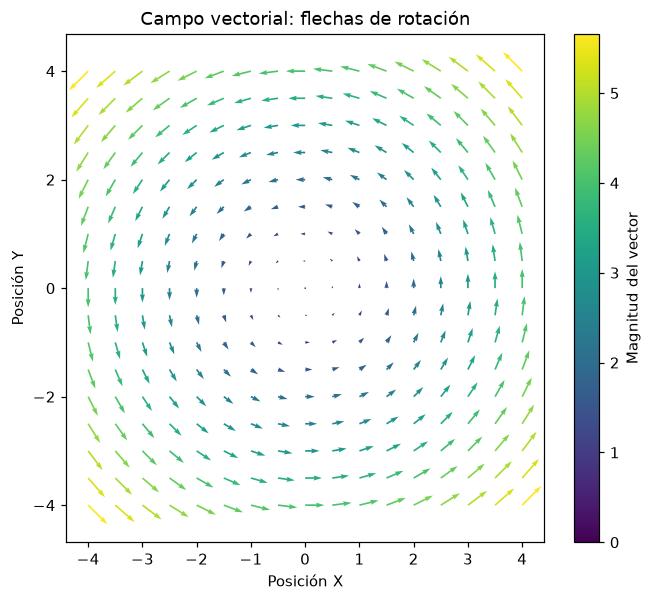

In [4]:
plt.figure(figsize=(7, 6))
flechas = plt.quiver(X, Y, U, V, M, cmap="viridis")
plt.colorbar(flechas, label="Magnitud del vector")
plt.title("Campo vectorial: flechas de rotación")
plt.xlabel("Posición X")
plt.ylabel("Posición Y")
plt.axis("equal")
plt.show()

**Resultado observado.** Las flechas formaron un remolino antihorario alrededor del origen, con flechas cortas y violetas cerca del centro y largas y amarillas hacia las esquinas. En el centro no se dibuja flecha alguna porque el vector es nulo. `plt.axis("equal")` fue necesario para que los ángulos de las flechas no se deformaran.

**Comprobación del aprendizaje.** El gráfico representa el vector de cada punto como una flecha, y las variables que lo controlan son `U` y `V` (dirección y longitud) y `M` (color).

### Bloque 4. Mostrar líneas de corriente

**Qué se hizo.** Se trazaron con `ax.streamplot` curvas tangentes al campo en cada uno de sus puntos, coloreadas por magnitud y con `density=1.1`. A diferencia de `quiver`, no se dibuja un símbolo por celda: Matplotlib integra trayectorias a partir de semillas repartidas por el dominio e interpola el campo entre los nodos de la grilla.

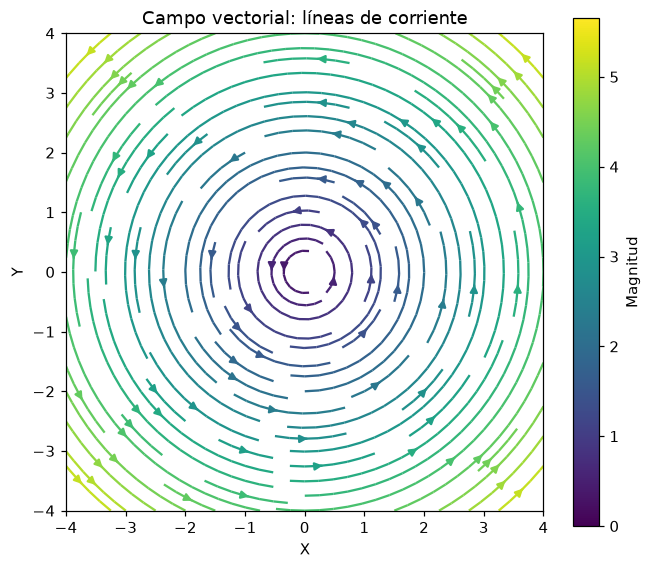

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
flujo = ax.streamplot(X, Y, U, V, color=M, cmap="viridis",
                      density=1.1)
fig.colorbar(flujo.lines, ax=ax, label="Magnitud")
ax.set_title("Campo vectorial: líneas de corriente")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_aspect("equal")
plt.show()

**Resultado observado.** Aparecieron circunferencias concéntricas recorridas en sentido antihorario, más amarillas (más rápidas) cuanto mayor el radio. Eran círculos porque seguir el campo significa resolver `x' = −y`, `y' = x`, cuya solución conserva `x² + y²`: la distancia al centro no cambia a lo largo de una trayectoria. Las líneas dieron el patrón global del giro, algo que con las flechas había que reconstruir mentalmente.

**Comprobación del aprendizaje.** El gráfico representa trayectorias que en cada punto son tangentes al vector del campo, y la variable que controla cuántas se dibujan es `density`.

### Bloque 5. Comparar una fuente y un sumidero

**Qué se hizo.** Se dibujaron en paralelo dos campos que solo se diferencian en el signo: fuente `(U, V) = (X, Y)` y sumidero `(U, V) = (−X, −Y)`. El objetivo fue ver que invertir el sentido de U y V basta para pasar de un comportamiento al opuesto.

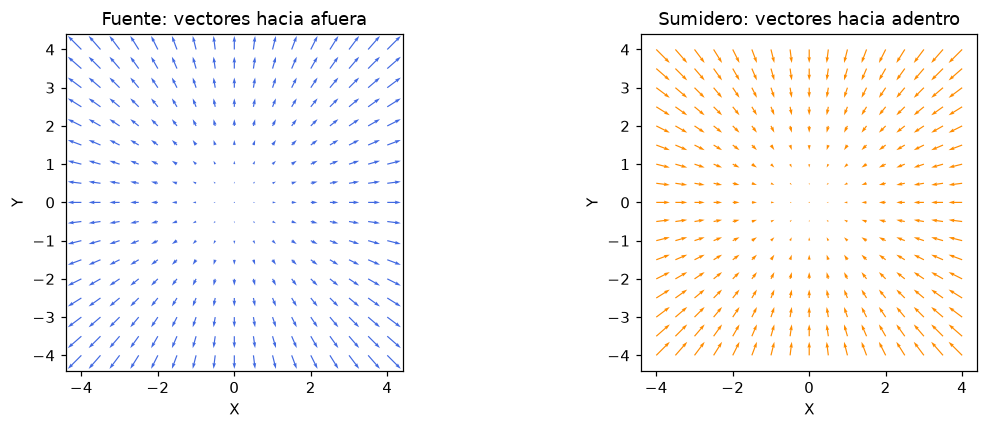

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Fuente: las flechas salen del origen
axes[0].quiver(X, Y, X, Y, color="royalblue")
axes[0].set_title("Fuente: vectores hacia afuera")

# Sumidero: las flechas apuntan al origen
axes[1].quiver(X, Y, -X, -Y, color="darkorange")
axes[1].set_title("Sumidero: vectores hacia adentro")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
plt.tight_layout()
plt.show()

**Resultado observado.** En la fuente las flechas radiaron desde el origen y en el sumidero convergieron hacia él, con la misma longitud en cada posición: solo cambió el sentido. En ambos casos la magnitud, igual a la distancia al origen, creció hacia afuera; el origen fue un punto de reposo (vector nulo) en los dos.

**Comprobación del aprendizaje.** Los gráficos representan flujos radiales opuestos, y la variable que los diferencia es el signo de `U` y `V`.

## 4. Retos resueltos individualmente

### Reto 1. Grilla de 17 × 17 a 33 × 33

**Enunciado.** Reemplazar la grilla de 17 × 17 por una de 33 × 33 puntos y comparar los gráficos de flechas: ¿cuándo se vuelve difícil leerlos?

Puntos: 1089 | paso: 0.25 | magnitud máxima: 5.66


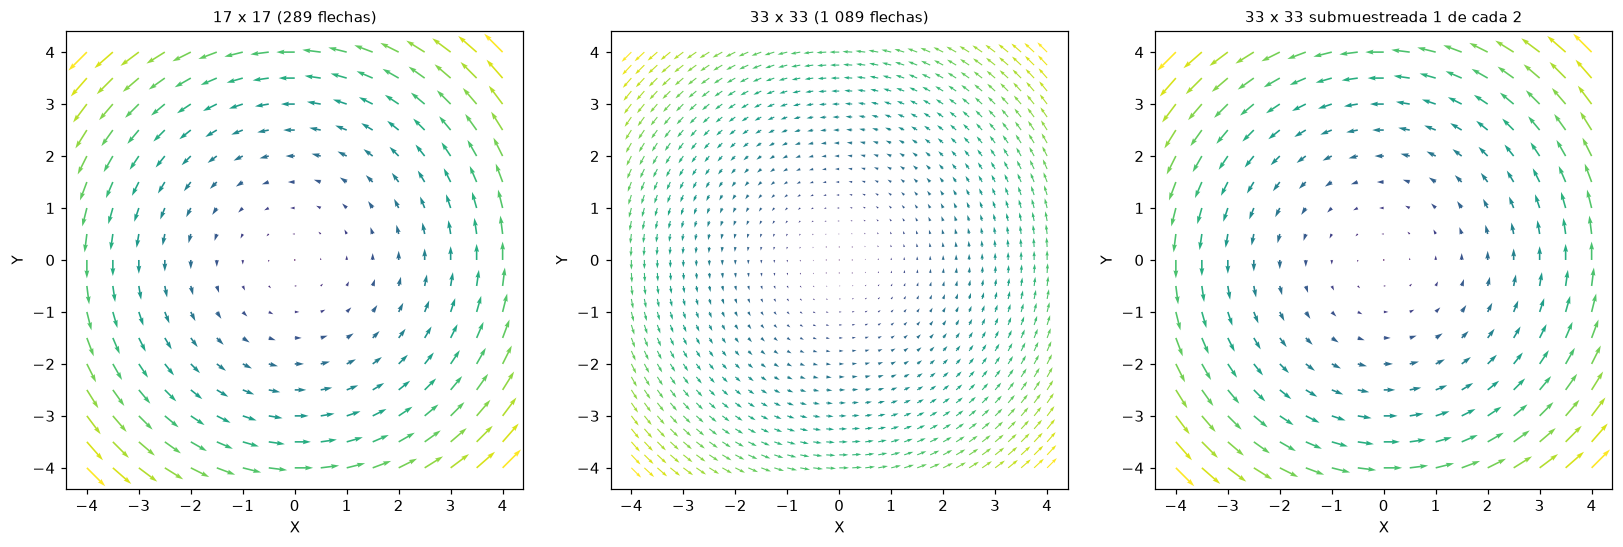

In [7]:
# Misma fórmula con una grilla de 33 x 33 (1 089 vectores)
x33 = np.linspace(-4, 4, 33)
X33, Y33 = np.meshgrid(x33, x33)
U33, V33 = -Y33, X33
M33 = np.sqrt(U33**2 + V33**2)
print("Puntos:", X33.size, "| paso:", x33[1] - x33[0], "| magnitud máxima:", round(M33.max(), 2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
casos = [("17 x 17 (289 flechas)", X, Y, U, V, M),
         ("33 x 33 (1 089 flechas)", X33, Y33, U33, V33, M33),
         ("33 x 33 submuestreada 1 de cada 2", X33[::2, ::2], Y33[::2, ::2], U33[::2, ::2], V33[::2, ::2], M33[::2, ::2])]
for ax, (titulo, xx, yy, uu, vv, mm) in zip(axes, casos):
    ax.quiver(xx, yy, uu, vv, mm, cmap="viridis")
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

**Análisis.** Con 33 × 33 (1 089 flechas, paso de 0,25) los gráficos se volvieron difíciles de leer en dos zonas distintas. **En el centro**, donde la magnitud es pequeña, las flechas quedaron reducidas a puntos y el color apenas se distinguía. **En la periferia**, donde la magnitud llega a 5,66, las flechas largas se acercaron a sus vecinas hasta rozarse y formaron franjas continuas en las que ya no se identifica la dirección de cada una. Es decir, el límite no lo marcó un número fijo de puntos sino la relación entre la longitud de la flecha y el espacio disponible, que depende de cuánto varía la magnitud en el campo. El tercer panel mostró una salida simple: **submuestrear** 1 de cada 2 puntos devolvió una imagen casi idéntica a la de 17 × 17, porque este campo es suave y 289 vectores ya capturan su estructura. Otras opciones serían reducir `scale` o normalizar las flechas y dejar la magnitud solo al color.

### Reto 2. Densidad de streamplot: 0,5 y 2,0

**Enunciado.** En `streamplot` cambiar `density=1.1` por 0,5 y después por 2,0, y comparar la cantidad de líneas.

density = 0.5: 28 líneas de corriente, 392 tramos dibujados


density = 1.1: 80 líneas de corriente, 1022 tramos dibujados


density = 2.0: 142 líneas de corriente, 3215 tramos dibujados


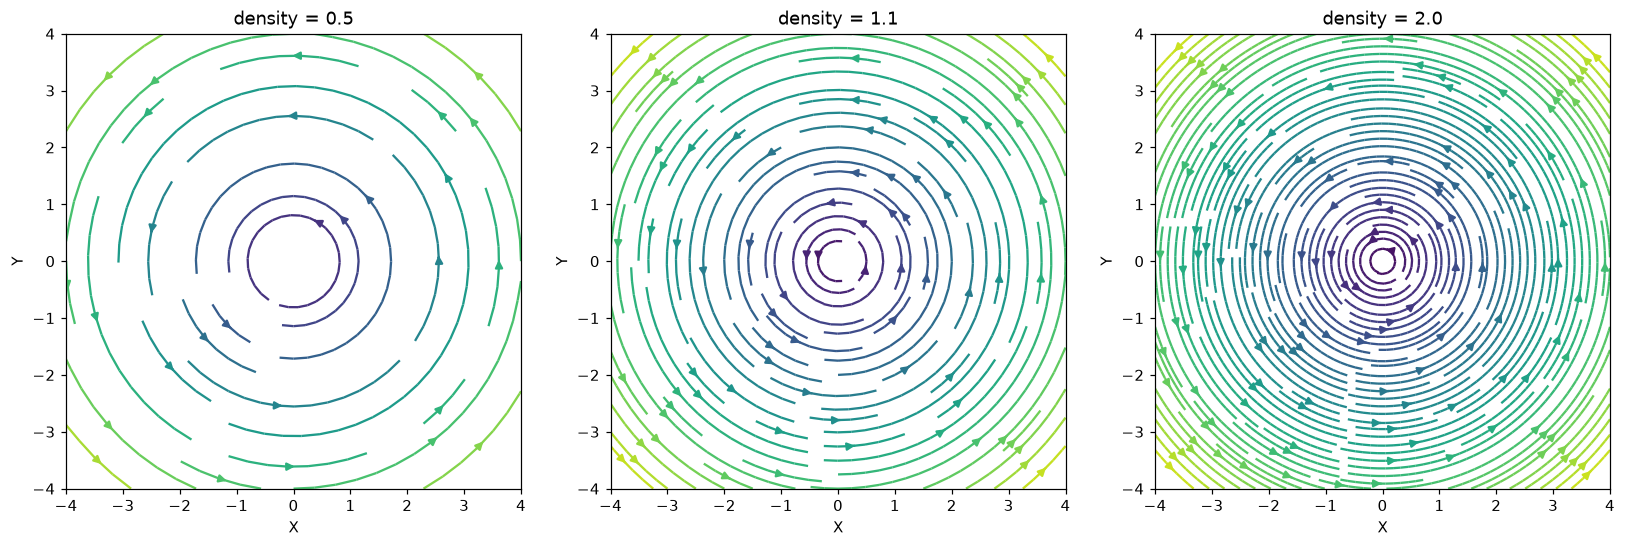

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, d in zip(axes, [0.5, 1.1, 2.0]):
    flujo = ax.streamplot(X, Y, U, V, color=M, cmap="viridis", density=d)
    ax.set_title(f"density = {d}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal")
    n_lineas = len(flujo.arrows.get_paths())          # una flecha por trayectoria
    n_tramos = len(flujo.lines.get_segments())        # tramos rectos que componen las líneas
    print(f"density = {d}: {n_lineas} líneas de corriente, {n_tramos} tramos dibujados")
plt.tight_layout()
plt.show()

**Análisis.** La consola contó 28 líneas con `density = 0,5`, 80 con 1,1 y 142 con 2,0 (392, 1 022 y 3 215 tramos dibujados). El crecimiento no fue proporcional: al cuadruplicar la densidad el número de líneas se multiplicó por ≈ 5 y el de tramos por ≈ 8. La razón es que `density` no dice «cuántas líneas», sino cuán fina es la rejilla de control: con 1 el dominio se divide en 30 × 30 celdas y cada celda admite como máximo una línea; con 0,5 hay 15 × 15 celdas y con 2,0 hay 60 × 60. Visualmente, con 0,5 aparecieron pocos anillos y grandes espacios vacíos, aunque el giro seguía reconociéndose; con 2,0 los anillos centrales se apretaron y las puntas de flecha se amontonaron. El campo es el mismo en los tres casos: subir la densidad no agregó información, solo detalle de dibujo, y pasado cierto punto estorba.

### Reto 3. Campo de silla: U = X, V = −Y

**Enunciado.** Crear un campo de silla con `U = X` y `V = -Y` y explicar hacia dónde apuntan las flechas.

En ( 3,  0) el vector es (+3, +0)
En ( 0,  3) el vector es (+0, -3)
En (-3,  0) el vector es (-3, +0)
En ( 0, -3) el vector es (+0, +3)
En ( 2,  2) el vector es (+2, -2)
En ( 0,  0) el vector es (+0, +0)

Campo                Divergencia  Rotacional
Rotación (-Y, X)             0.0         2.0
Fuente (X, Y)                2.0         0.0
Sumidero (-X, -Y)           -2.0         0.0
Silla (X, -Y)                0.0         0.0


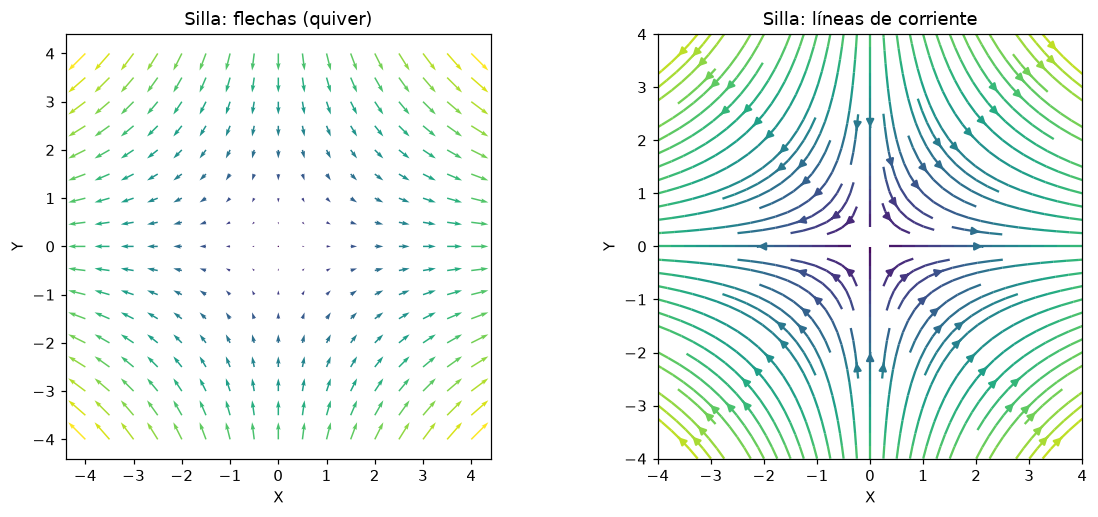

In [9]:
Us, Vs = X, -Y                       # campo de silla
Ms = np.sqrt(Us**2 + Vs**2)

# Vectores en puntos representativos (columna = x, fila = y)
for (px, py) in [(3, 0), (0, 3), (-3, 0), (0, -3), (2, 2), (0, 0)]:
    i, j = int((py + 4) / 0.5), int((px + 4) / 0.5)
    print(f"En ({px:>2}, {py:>2}) el vector es ({Us[i, j] + 0.0:+.0f}, {Vs[i, j] + 0.0:+.0f})")   # + 0.0 evita el "-0"

# Divergencia y rotacional numéricos de los cuatro campos del laboratorio
campos = {"Rotación (-Y, X)": (-Y, X), "Fuente (X, Y)": (X, Y),
          "Sumidero (-X, -Y)": (-X, -Y), "Silla (X, -Y)": (X, -Y)}
print()
print(f"{'Campo':<20}{'Divergencia':>12}{'Rotacional':>12}")
for nombre, (u, v) in campos.items():
    dudx, dudy = np.gradient(u, x, axis=1), np.gradient(u, y, axis=0)
    dvdx, dvdy = np.gradient(v, x, axis=1), np.gradient(v, y, axis=0)
    print(f"{nombre:<20}{(dudx + dvdy).mean():>12.1f}{(dvdx - dudy).mean():>12.1f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].quiver(X, Y, Us, Vs, Ms, cmap="viridis")
axes[0].set_title("Silla: flechas (quiver)")
axes[1].streamplot(X, Y, Us, Vs, color=Ms, cmap="viridis", density=1.1)
axes[1].set_title("Silla: líneas de corriente")
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
plt.tight_layout()
plt.show()

**Análisis.** En el campo `(U, V) = (X, −Y)` el eje X empuja hacia afuera y el eje Y atrae hacia adentro: en (±3, 0) el vector es (±3, 0), alejándose del origen, y en (0, ±3) es (0, ∓3), acercándose a él. En el resto del plano las flechas combinan ambos efectos: en (2, 2) el vector es (2, −2), que desciende y se desplaza a la derecha. Las líneas de corriente son hipérbolas (`x·y = constante`): el fluido se acerca al origen siguiendo el eje Y, se curva y sale siguiendo el eje X. El origen es un punto de reposo (vector nulo) pero **no es fuente ni sumidero**: entra tanta «corriente» como sale, y la tabla lo confirmó con divergencia 0 y rotacional 0. Eso lo distingue de la fuente (divergencia +2), del sumidero (−2) y de la rotación (rotacional 2): cuatro campos de fórmulas casi iguales con comportamientos cualitativamente distintos.

## 5. Preguntas de interpretación

**1. ¿Qué información guarda cada punto del campo vectorial?**  
Un vector de dos componentes (U, V): cuánto avanza en horizontal y en vertical. De ellas se deducen su dirección (el ángulo) y su magnitud (el tamaño). El lugar (X, Y) no forma parte del vector: es dónde está anclado.

**2. ¿Cuál es la diferencia entre X, Y y U, V?**  
(X, Y) son las coordenadas del punto del dominio; (U, V) son los valores que el campo toma en ese punto. Por ejemplo, en (X, Y) = (2, 0) el campo vale (U, V) = (0, 2).

**3. ¿Qué expresa la magnitud M y por qué en el centro es cero?**  
M = √(U² + V²) es la longitud del vector, su intensidad sin dirección. En el centro X = Y = 0, luego U = −Y = 0 y V = X = 0: el vector es nulo y su longitud, cero. Es un punto de reposo del campo de rotación.

**4. ¿Qué diferencia existe entre quiver y streamplot?**  
`quiver` muestra el campo localmente: una flecha por punto muestreado, con longitud proporcional a la magnitud, y se satura si hay demasiados puntos. `streamplot` calcula trayectorias continuas tangentes al campo; da el patrón global y la conectividad del flujo, pero la magnitud solo aparece por color y la densidad de líneas es una elección de dibujo, no un dato.

**5. ¿En qué se distinguen una fuente, un sumidero y un campo de rotación?**  
En la fuente los vectores salen radialmente del centro (divergencia +2); en el sumidero entran (−2); en la rotación son tangenciales, sin componente radial: no hay entrada ni salida (divergencia 0) pero sí circulación (rotacional +2). El campo de silla es otro caso: divergencia y rotacional nulos, con entrada por un eje y salida por el otro.

## 6. Conclusiones

1. Un campo vectorial guarda en cada punto dos números (U, V) que combinan dirección y magnitud, y por eso exige distinguir siempre la posición (X, Y) del dato (U, V). Aprendí que a partir de ese par se puede derivar un campo escalar (la magnitud) y que otras propiedades —divergencia, rotacional— aparecen al ver cómo varían los vectores entre vecinos: fuente, sumidero, rotación y silla son cuatro comportamientos distintos de fórmulas casi idénticas.

2. Interpreto los gráficos considerando que `quiver` es una muestra local y `streamplot` una reconstrucción global: las flechas son fieles al dato pero se vuelven ilegibles si se multiplican los puntos (hubo que submuestrear), mientras que las líneas de corriente muestran la estructura del flujo pero dependen de `density`, que modifica la cantidad de líneas sin modificar el campo. Un buen gráfico vectorial combina ambos, con ejes de igual escala y una barra de color para la magnitud.